# 00 · Connection

Block 0 check: connect to MCP, find the tools we need, read the stage, acquire one HAADF image and read it back from Tiled.

**Before running (twin):** `uv run python scripts/twin.py start` in a terminal. Stop it later with `uv run python scripts/twin.py stop`.

**Real microscope:** set `STEM_REAL_MCP_URL` in `.env` and `INSTRUMENT = "real"`.

In [1]:
INSTRUMENT = "real"   # "twin" or "real"

In [2]:
import json

import matplotlib.pyplot as plt

from stem_agent.config import TOOLS
from stem_agent.data import tiled_io
from stem_agent.mcp import session

client = session.connect(INSTRUMENT)
tools = await client.list_tools()
print(f"{client.url}: {len(tools)} tools")

http://10.46.217.241:8000/mcp: 72 tools


In [3]:
tools

{'get_data_from_key': Tool(name='get_data_from_key', title='Get Data From Key', description='Read a remote DATA/Tiled key and return dataset metadata plus small previews.', inputSchema={'properties': {'key': {'type': 'string'}, 'max_values': {'default': 64, 'type': 'integer'}, 'data_device_address': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None}}, 'required': ['key'], 'type': 'object', 'additionalProperties': False}, outputSchema={'type': 'object', 'additionalProperties': True}, icons=None, annotations=None, meta={'fastmcp': {'tags': []}}, execution=None),
 'list_devices': Tool(name='list_devices', title='List Devices', description='List available devices filtered by blocked classes.', inputSchema={'properties': {}, 'type': 'object', 'additionalProperties': False}, outputSchema={'properties': {'result': {'items': {'type': 'string'}, 'type': 'array'}}, 'required': ['result'], 'type': 'object', 'x-fastmcp-wrap-result': True}, icons=None, annotations=None, meta={'fastm

## Tools we need
Every short name in `config.TOOLS` must map to a tool on the server.

In [3]:
missing = []
for short in TOOLS:
    name = session.tool_name(short)
    tool = tools.get(name)
    args = list((tool.inputSchema or {}).get("properties", {})) if tool else []
    print(f"{'ok     ' if tool else 'MISSING'} {short:<20} {name}({', '.join(args)})")
    if tool is None:
        missing.append(short)
print("missing:", missing or "none")

ok      list_devices         list_devices()
ok      get_tiled_config     DATA_get_config()
ok      get_stage            AutoScriptMicroscope_get_stage()
ok      move_stage           AutoScriptMicroscope_move_stage(position)
ok      get_fov              AutoScriptMicroscope_get_fov()
ok      set_fov              AutoScriptMicroscope_set_fov(fov)
ok      get_defocus          AutoScriptMicroscope_get_defocus()
ok      get_parameters       AutoScriptMicroscope_get_parameters()
ok      acquire_image        AutoScriptMicroscope_acquire_scanned_image(detector_list)
ok      acquire_spectrum     AutoScriptMicroscope_acquire_spectrum(detector_name)
ok      place_beam           AutoScriptMicroscope_place_beam(position)
ok      blank_beam           AutoScriptMicroscope_blank_beam()
ok      correct_aberration   CEOSCorrector_correct_aberration(args)
ok      corrector_info       CEOSCorrector_get_info()
missing: none


## Read-only calls

In [4]:
stage = await session.call("get_stage")
fov = await session.call("get_fov")
print("stage [x, y, z, alpha, beta]:", stage)
print(f"FOV: {fov * 1e9:.1f} nm")

stage [x, y, z, alpha, beta]: [0.0, 0.0, 0.0, 0.0, 0.0]
FOV: 20.0 nm


## One HAADF image
MCP returns the Tiled key; the full image is read from Tiled over HTTP.

Tiled http://127.0.0.1:9091
key stem_image_HAADF_20261103T193059854078.h5
shape (512, 512), range [0.000326, 1.05]


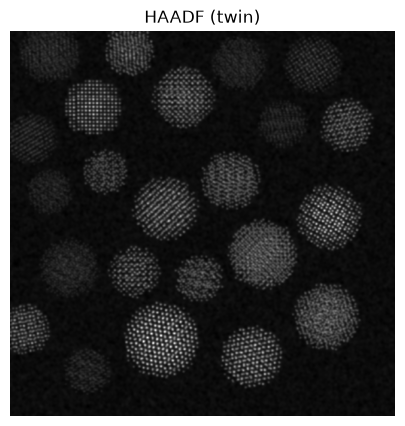

In [5]:
uri = json.loads(await session.call("get_tiled_config"))["uri"]
tiled_io.connect(uri)

key = await session.call("acquire_image", ["haadf"])
image = tiled_io.read_image(key)
print(f"Tiled {uri}\nkey {key}\nshape {image.shape}, range [{image.min():.3g}, {image.max():.3g}]")

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(image, cmap="gray")
ax.set_title(f"HAADF ({INSTRUMENT})")
ax.axis("off")
plt.show()